# Práctica 6 · Detección de Rostros con Ventana Deslizante e Image Pyramid

**Objetivo.** Detectar rostros humanos en escenas con fondos complejos y rostros de distinto tamaño, resolviendo los dos desafíos clásicos de la detección de objetos:

| Desafío | Problema | Solución |
|---|---|---|
| **1 · Ubicación** | El objeto puede estar en cualquier región | **Ventana deslizante** (`sliding_window`) |
| **2 · Tamaño** | El objeto puede ser mayor (2a) o menor (2b) que la ventana | **Pirámide de imágenes** (`image_pyramid`), conservando el *aspect ratio* |

**Pipeline.** pirámide → ventana deslizante → clasificación por lotes con una CNN preentrenada (ResNet-10 SSD, pesos oficiales de OpenCV) → mapeo inverso a la imagen original → NMS → recuadro verde con su probabilidad.

**Mapeo inverso.** Una ventana en $(x, y)$ de un nivel con factor acumulado $s = \text{scale}^{\,l}$ corresponde en la imagen original a
$x_1=\mathrm{round}(x\,s),\; y_1=\mathrm{round}(y\,s),\; x_2=\mathrm{round}((x+w)\,s),\; y_2=\mathrm{round}((y+h)\,s)$.

### Decisiones de diseño (ajustes respecto a la guía, y por qué)
1. **Modelo.** Se usa `cv2.dnn.readNetFromCaffe` con `deploy.prototxt` + `res10_300x300_ssd_iter_140000.caffemodel` (pesos reales, sin cabezales aleatorios). Todas las probabilidades salen de la inferencia de la red.
2. **Puntaje por ventana con alineación.** El SSD es un *detector* (devuelve cajas), no un clasificador de parches. Cada caja del SSD se convierte a cuadrada (lado $\sqrt{w\,h}$) y se mide su **alineación** = IoU con la ventana. Solo cuentan las cajas con alineación $\ge 0.60$; el puntaje de la ventana es su confianza. Sin este filtro, cualquier ventana desplazada que contenga parte del rostro hereda confianza ≈ 1.0 (en una primera versión esto producía 3 y 10 recuadros sobre un mismo rostro).
3. **Prioridad en NMS = confianza × alineación.** Muchas ventanas tienen confianza ≈ 1.0 (empates); se conserva la mejor centrada. Se reporta la confianza real de la red.
4. **NMS + contención.** Además del IoU > 0.3, se eliminan cajas con > 40 % de su área dentro de otra mejor: una ventana de 96 px *dentro* de un rostro de 190 px tiene IoU ≈ 0.26 y el NMS clásico no la quita. (Con 0.60 sobrevivía un recuadro espurio sobre el mentón del Caso 2, con 49 % de su área dentro de la caja principal.)
5. **Contexto (margen neutro del 50 % del lado) alrededor de cada ventana.** Un parche de 96 px ampliado 3× a 300×300 queda fuera de la distribución del SSD y produce falsos positivos (p. ej. 0.978 sobre la cuchara del Caso 3). El margen los reduce (máx. 0.53). La ablación 2×2 de la sección 7 muestra el aporte de 2 y 5.
6. **Umbral 0.90** (la guía pide ≥ 0.80). Con 0.80 el modo *Paso Fino* aceptaba una ventana sobre el transbordador del fondo (82.7 %). Ojo: este valor se eligió mirando esa imagen; para una conclusión general haría falta un conjunto de validación.
7. **`min_size`.** La pirámide se detiene cuando un nivel es menor que la ventana (96 px).
8. **Caso 2.** Retrato construido con un recorte ampliado de `data.astronaut()` (rostro ≈ 200×260 px ≫ ventana de 96 px), que obliga a detectar en niveles superiores de la pirámide.

> **Tiempo de ejecución.** La red solo admite entrada 300×300 y corre en CPU (`cv2.dnn`), así que el escaneo es costoso; la configuración *Paso Fino* (≈11 mil ventanas) es la más lenta. Con GPU T4 no se acelera `cv2.dnn`, pero Kaggle ofrece 4 núcleos de CPU.

## 1 · Entorno y dependencias

In [1]:
import os, sys, json, time, subprocess
import cv2

# La serie 5.x de OpenCV eliminó el importador de Caffe: se necesita la 4.x
if not hasattr(cv2.dnn, "readNetFromCaffe"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python-headless<5"], check=True)
    raise RuntimeError("Se instaló OpenCV 4.x. Reinicia el kernel (Run > Restart) y ejecuta de nuevo.")

print("OpenCV", cv2.__version__)
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.abspath(".")
os.chdir(OUT_DIR)
print("Directorio de salida:", OUT_DIR)

OpenCV 4.14.0
Directorio de salida: /kaggle/working


## 2 · Módulo de la práctica (`practica_6_deteccion_rostros.py`)
Esta celda escribe el **script autocontenido** que también es un entregable: funciones modulares (`image_pyramid`, `sliding_window`, `puntuar_lote`, `non_max_suppression`, `detect_faces`, `draw_detections`) y un bloque `if __name__ == '__main__'` para procesar una imagen por consola. El resto del notebook lo importa, de modo que **notebook y script ejecutan exactamente el mismo código**.

In [2]:
%%writefile practica_6_deteccion_rostros.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Práctica 6: Detección de Rostros con Ventana Deslizante + Pirámide de Imágenes
==============================================================================

Pipeline clásico-convolucional:
  1. Pirámide de imágenes (multiescala, conserva la relación de aspecto).
  2. Ventana deslizante de tamaño fijo sobre cada nivel de la pirámide.
  3. Cada ventana se clasifica con una red convolucional PREENTRENADA
     (ResNet-10 SSD de Caffe, cargada con cv2.dnn.readNetFromCaffe), en lotes.
  4. Mapeo inverso de las ventanas aceptadas a coordenadas de la imagen original.
  5. Supresión de No Máximos (NMS) para dejar un único recuadro por rostro.

Uso por consola:
    python practica_6_deteccion_rostros.py ruta/imagen.jpg --step 16 --scale 1.25

Requisitos: numpy, opencv-python (serie 4.x: la serie 5.x eliminó el importador Caffe).
"""
import argparse
import json
import os
import sys
import time
import urllib.request

import cv2
import numpy as np

# --------------------------------------------------------------------------
# Modelo preentrenado (pesos oficiales de OpenCV)
# --------------------------------------------------------------------------
PROTO_NAME = "deploy.prototxt"
MODEL_NAME = "res10_300x300_ssd_iter_140000.caffemodel"
PROTO_URL = ("https://raw.githubusercontent.com/opencv/opencv/4.x/"
             "samples/dnn/face_detector/deploy.prototxt")
MODEL_URL = ("https://raw.githubusercontent.com/opencv/opencv_3rdparty/"
             "dnn_samples_face_detector_20170830/" + MODEL_NAME)
MEAN_BGR = (104.0, 177.0, 123.0)   # media con la que fue entrenada la red
NET_INPUT = (300, 300)             # tamaño de entrada fijo del SSD


def descargar_modelo(directorio="."):
    """Descarga deploy.prototxt y los pesos .caffemodel si no existen."""
    os.makedirs(directorio, exist_ok=True)
    rutas = []
    for nombre, url in ((PROTO_NAME, PROTO_URL), (MODEL_NAME, MODEL_URL)):
        ruta = os.path.join(directorio, nombre)
        if not os.path.exists(ruta) or os.path.getsize(ruta) < 1000:
            print(f"[modelo] descargando {nombre} ...")
            urllib.request.urlretrieve(url, ruta)
        rutas.append(ruta)
    return rutas[0], rutas[1]


def cargar_red(directorio="."):
    """Carga la red ResNet-10 SSD con pesos oficiales (sin inicialización aleatoria)."""
    if not hasattr(cv2.dnn, "readNetFromCaffe"):
        raise RuntimeError(
            f"OpenCV {cv2.__version__} no incluye el importador Caffe. "
            "Instala la serie 4.x: pip install 'opencv-python-headless<5'")
    proto, pesos = descargar_modelo(directorio)
    return cv2.dnn.readNetFromCaffe(proto, pesos)


# --------------------------------------------------------------------------
# Desafío 2: variabilidad de tamaño -> Pirámide de imágenes
# --------------------------------------------------------------------------
def image_pyramid(image, scale=1.25, min_size=(96, 96)):
    """
    Generador de la pirámide. En el nivel l la imagen se reduce por scale**l
    (mismo factor en ancho y alto => se preserva el aspect ratio).
    Devuelve (level, scale_factor, resized_image), con scale_factor = scale**level
    respecto a la imagen original. Se detiene cuando algún lado < min_size.
    """
    h0, w0 = image.shape[:2]
    yield 0, 1.0, image
    level = 0
    while True:
        level += 1
        s = scale ** level                      # factor acumulado desde el original
        w, h = int(round(w0 / s)), int(round(h0 / s))
        if w < min_size[0] or h < min_size[1]:
            break
        yield level, s, cv2.resize(image, (w, h), interpolation=cv2.INTER_AREA)


# --------------------------------------------------------------------------
# Desafío 1: variabilidad de ubicación -> Ventana deslizante
# --------------------------------------------------------------------------
def sliding_window(image, step_size, window_size):
    """Recorre la imagen con una ventana fija. Devuelve (x, y, patch)."""
    win_w, win_h = window_size
    H, W = image.shape[:2]
    for y in range(0, H - win_h + 1, step_size):
        for x in range(0, W - win_w + 1, step_size):
            yield x, y, image[y:y + win_h, x:x + win_w]


# --------------------------------------------------------------------------
# Clasificación por lotes con la red convolucional
# --------------------------------------------------------------------------
def puntuar_lote(net, patches, min_cover=0.60, context=0.50):
    """
    Evalúa un lote de parches (ventanas cuadradas) con UN solo net.forward().

    1) Contexto: cada parche se rodea con un margen neutro (color medio del
       entrenamiento, = 0 tras restar la media) de `context` x lado de la ventana
       por cada lado. Sin él, un parche de 96 px ampliado a 300x300 deja un
       "primer plano" fuera de distribución y el SSD alucina rostros en objetos
       (p. ej. ~0.98 de confianza sobre una cuchara en la imagen del café).
    2) Puntaje de ventana: el SSD devuelve cajas de rostro con su probabilidad.
       Cada caja se convierte a cuadrada (lado = sqrt(ancho*alto), mismo centro)
       y se mide su ALINEACIÓN = IoU(caja cuadrada, ventana completa). Solo
       cuentan las cajas con alineación >= min_cover; el puntaje de la ventana es
       la máxima confianza entre ellas. Así, una ventana desplazada o de tamaño
       distinto al rostro no hereda su confianza y el recuadro se ajusta al rostro.
    Devuelve (confianzas, alineaciones), ambos de longitud len(patches).
    Las confianzas son las probabilidades reales de la red, continuas en [0, 1].
    """
    win = patches[0].shape[0]
    pad = int(round(context * win))
    canvas = win + 2 * pad
    if pad > 0:
        patches = [cv2.copyMakeBorder(p, pad, pad, pad, pad, cv2.BORDER_CONSTANT,
                                      value=MEAN_BGR) for p in patches]
    blob = cv2.dnn.blobFromImages(patches, 1.0, NET_INPUT, MEAN_BGR,
                                  swapRB=False, crop=False)
    net.setInput(blob)
    dets = net.forward()[0, 0]                  # (N_det, 7): id, clase, conf, x1, y1, x2, y2
    scores = np.zeros(len(patches), dtype=np.float32)
    aligns = np.zeros(len(patches), dtype=np.float32)
    if dets.shape[0] == 0:
        return scores, aligns
    ids = dets[:, 0].astype(int)
    conf = dets[:, 2]
    # cajas normalizadas del lienzo -> coordenadas relativas a la ventana [0,1]
    b = (dets[:, 3:7] * canvas - pad) / float(win)
    w = np.clip(b[:, 2] - b[:, 0], 0, None)
    h = np.clip(b[:, 3] - b[:, 1], 0, None)
    side = np.sqrt(w * h)
    cx, cy = (b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2
    iw = np.clip(np.minimum(cx + side / 2, 1) - np.maximum(cx - side / 2, 0), 0, None)
    ih = np.clip(np.minimum(cy + side / 2, 1) - np.maximum(cy - side / 2, 0), 0, None)
    inter = iw * ih
    align = inter / (1.0 + side * side - inter + 1e-9)
    ok = (ids >= 0) & (ids < len(patches)) & (conf > 0) & (align >= min_cover)
    np.maximum.at(scores, ids[ok], conf[ok])
    mejor = ok & (conf >= scores[np.clip(ids, 0, len(patches) - 1)])
    aligns[ids[mejor]] = align[mejor]
    return scores, aligns


# --------------------------------------------------------------------------
# Supresión de No Máximos (vectorizada)
# --------------------------------------------------------------------------
def non_max_suppression(boxes, scores, overlap_thresh=0.3, contain_thresh=None):
    """
    NMS sobre cajas [x1, y1, x2, y2]. Ordena por score descendente, calcula el
    IoU de la mejor caja contra todas las restantes (vectorizado) y elimina las
    que se solapan más de overlap_thresh. Devuelve los índices conservados.

    Extensión opcional (contain_thresh): también elimina las cajas cuya
    intersección con la mejor caja supera esa fracción de SU PROPIA área, es
    decir, cajas pequeñas contenidas dentro de una mayor (el IoU de una caja de
    96 px dentro de otra de 190 px es ~0.25 y el NMS clásico no las quitaría).
    """
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    scores = np.asarray(scores, dtype=np.float64)
    if boxes.shape[0] == 0:
        return np.array([], dtype=int)
    x1, y1, x2, y2 = boxes.T
    areas = (x2 - x1) * (y2 - y1)
    orden = np.argsort(-scores)
    keep = []
    while orden.size > 0:
        i = orden[0]
        keep.append(i)
        resto = orden[1:]
        xx1 = np.maximum(x1[i], x1[resto])
        yy1 = np.maximum(y1[i], y1[resto])
        xx2 = np.minimum(x2[i], x2[resto])
        yy2 = np.minimum(y2[i], y2[resto])
        inter = np.clip(xx2 - xx1, 0, None) * np.clip(yy2 - yy1, 0, None)
        iou = inter / (areas[i] + areas[resto] - inter + 1e-9)
        suprimir = iou > overlap_thresh
        if contain_thresh is not None:
            suprimir |= inter / (np.minimum(areas[i], areas[resto]) + 1e-9) > contain_thresh
        orden = resto[~suprimir]
    return np.array(keep, dtype=int)


# --------------------------------------------------------------------------
# Detector completo
# --------------------------------------------------------------------------
def detect_faces(image_bgr, net, window_size=(96, 96), step_size=16, scale=1.25,
                 conf_threshold=0.90, overlap_thresh=0.3, batch_size=32,
                 min_cover=0.60, context=0.50, contain_thresh=0.40, min_size=None):
    """
    Ejecuta pirámide + ventana deslizante + red + mapeo inverso + NMS.
    Los parches de TODOS los niveles se acumulan en lotes de `batch_size`.
    """
    win_w, win_h = window_size
    # un nivel menor que la ventana no puede contener ni una ventana completa
    min_size = (max(win_w, (min_size or (0, 0))[0]), max(win_h, (min_size or (0, 0))[1]))
    H0, W0 = image_bgr.shape[:2]

    t0 = time.perf_counter()
    raw_boxes, raw_scores, raw_rank = [], [], []
    niveles, ventanas_por_nivel = 0, []
    total = 0
    buf_patches, buf_meta = [], []

    def vaciar_lote():
        if not buf_patches:
            return
        sc, al = puntuar_lote(net, buf_patches, min_cover, context)
        for (x, y, s), p, a in zip(buf_meta, sc, al):
            if p >= conf_threshold:
                # Mapeo inverso a la imagen original (factor acumulado s)
                x1o, y1o = int(round(x * s)), int(round(y * s))
                x2o, y2o = int(round((x + win_w) * s)), int(round((y + win_h) * s))
                raw_boxes.append([max(0, x1o), max(0, y1o), min(W0, x2o), min(H0, y2o)])
                raw_scores.append(float(p))
                raw_rank.append(float(p * a))   # prioridad en NMS: confianza x alineación
        buf_patches.clear()
        buf_meta.clear()

    for level, s, resized in image_pyramid(image_bgr, scale, min_size):
        niveles += 1
        n_nivel = 0
        for x, y, patch in sliding_window(resized, step_size, window_size):
            buf_patches.append(patch)
            buf_meta.append((x, y, s))
            n_nivel += 1
            if len(buf_patches) >= batch_size:
                vaciar_lote()
        ventanas_por_nivel.append(n_nivel)
        total += n_nivel
    vaciar_lote()

    raw_boxes = np.array(raw_boxes, dtype=int).reshape(-1, 4)
    raw_scores = np.array(raw_scores, dtype=float)
    raw_rank = np.array(raw_rank, dtype=float)
    # NMS ordena por confianza x alineación (desempata a favor de la ventana mejor
    # centrada cuando varias tienen confianza ~1.0); se reporta la confianza real.
    keep = non_max_suppression(raw_boxes, raw_rank, overlap_thresh, contain_thresh)
    elapsed = time.perf_counter() - t0
    return {
        "boxes": raw_boxes[keep], "scores": raw_scores[keep],
        "raw_boxes": raw_boxes, "raw_scores": raw_scores,
        "niveles": niveles, "ventanas_por_nivel": ventanas_por_nivel,
        "total_ventanas": total, "detecciones_brutas": int(len(raw_boxes)),
        "detecciones_finales": int(len(keep)), "tiempo_s": elapsed,
    }


# --------------------------------------------------------------------------
# Visualización
# --------------------------------------------------------------------------
def draw_detections(image_bgr, boxes, scores, color=(0, 255, 0), thickness=3):
    """Dibuja recuadros verdes (3 px) con el texto 'Rostro: XX.X%'."""
    out = image_bgr.copy()
    fs = max(0.5, min(out.shape[:2]) / 600.0)
    for (x1, y1, x2, y2), sc in zip(boxes, scores):
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), color, thickness)
        txt = f"Rostro: {sc * 100:.1f}%"
        (tw, th), base = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, fs, 2)
        # etiqueta justo encima del borde (sin tapar el trazo); si no cabe, debajo
        ty = int(y1) - thickness - base - 2 if y1 - th - base - thickness - 8 > 0 else int(y2) + th + thickness + 4
        tx = int(min(max(x1, 0), max(out.shape[1] - tw - 2, 0)))
        cv2.rectangle(out, (tx, ty - th - 4), (tx + tw, ty + base), (0, 0, 0), -1)
        cv2.putText(out, txt, (tx, ty), cv2.FONT_HERSHEY_SIMPLEX, fs, color, 2, cv2.LINE_AA)
    return out


# --------------------------------------------------------------------------
# Línea de comandos
# --------------------------------------------------------------------------
def main(argv=None):
    ap = argparse.ArgumentParser(description="Detección de rostros: ventana deslizante + pirámide")
    ap.add_argument("imagen", help="ruta de la imagen a procesar")
    ap.add_argument("--step", type=int, default=16, help="paso de la ventana (8, 16, 24)")
    ap.add_argument("--scale", type=float, default=1.25, help="factor de la pirámide (1.15-1.40)")
    ap.add_argument("--ventana", type=int, default=96, help="lado de la ventana en px")
    ap.add_argument("--conf", type=float, default=0.90, help="umbral de confianza (>= 0.80)")
    ap.add_argument("--nms", type=float, default=0.30, help="umbral de solape del NMS")
    ap.add_argument("--alineacion", type=float, default=0.60,
                    help="alineación mínima caja-ventana (IoU) para aceptar una ventana")
    ap.add_argument("--contencion", type=float, default=0.40,
                    help="suprime cajas contenidas en otra mejor (fracción de su área)")
    ap.add_argument("--batch", type=int, default=32, help="tamaño de lote")
    ap.add_argument("--contexto", type=float, default=0.50,
                    help="margen de contexto alrededor de cada ventana (fracción del lado)")
    ap.add_argument("--max-lado", type=int, default=800,
                    help="reduce imágenes más grandes (ahorra tiempo); 0 = no reducir")
    ap.add_argument("--modelo-dir", default="modelo", help="carpeta del modelo Caffe")
    ap.add_argument("--salida", default="resultado_deteccion.png", help="imagen de salida")
    ap.add_argument("--json", default=None, help="guardar detecciones en JSON (opcional)")
    a = ap.parse_args(argv)

    img = cv2.imread(a.imagen)
    if img is None:
        sys.exit(f"No se pudo leer la imagen: {a.imagen}")
    factor = 1.0
    if a.max_lado and max(img.shape[:2]) > a.max_lado:
        factor = a.max_lado / max(img.shape[:2])
        img = cv2.resize(img, None, fx=factor, fy=factor, interpolation=cv2.INTER_AREA)
        print(f"[info] imagen reducida x{factor:.3f} para acelerar el escaneo")

    net = cargar_red(a.modelo_dir)
    r = detect_faces(img, net, (a.ventana, a.ventana), a.step, a.scale, a.conf,
                     a.nms, a.batch, min_cover=a.alineacion, context=a.contexto,
                     contain_thresh=a.contencion)
    print(f"Niveles: {r['niveles']} | Ventanas: {r['total_ventanas']} | "
          f"Brutas: {r['detecciones_brutas']} | Finales: {r['detecciones_finales']} | "
          f"Tiempo: {r['tiempo_s']:.1f} s")
    for b, s in zip(r["boxes"], r["scores"]):
        print(f"  Rostro {s * 100:.1f}%  caja={b.tolist()}")
    cv2.imwrite(a.salida, draw_detections(img, r["boxes"], r["scores"]))
    print(f"Resultado guardado en {a.salida}")
    if a.json:
        with open(a.json, "w", encoding="utf-8") as f:
            json.dump({"boxes": r["boxes"].tolist(), "scores": r["scores"].tolist(),
                       "factor_reduccion": factor}, f, indent=2)


if __name__ == "__main__":
    main()


Writing practica_6_deteccion_rostros.py


In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from skimage import data
from IPython.display import display

import practica_6_deteccion_rostros as p6
from practica_6_deteccion_rostros import (cargar_red, image_pyramid, sliding_window,
                                          non_max_suppression, detect_faces, draw_detections)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# ---- Hiperparámetros globales ----
WINDOW    = (96, 96)   # ventana deslizante
CONF_THR  = 0.90       # umbral de confianza (>= 0.80 pedido en la guía)
NMS_THR   = 0.30       # solape máximo permitido en NMS
BATCH     = 32         # tamaño de lote para net.forward()
MIN_COVER = 0.60       # alineación mínima (IoU caja cuadrada-ventana)
CONTAIN   = 0.40       # NMS por contención
CONTEXT   = 0.50       # margen de contexto (fracción del lado de la ventana)

rgb2bgr = lambda im: cv2.cvtColor(im, cv2.COLOR_RGB2BGR)
bgr2rgb = lambda im: cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

def detectar(img_bgr, step, scale, context=CONTEXT, min_cover=MIN_COVER):
    return detect_faces(img_bgr, net, WINDOW, step, scale, CONF_THR, NMS_THR,
                        BATCH, min_cover, context, CONTAIN)

net = cargar_red(os.path.join(OUT_DIR, "modelo"))   # descarga pesos oficiales (Internet: On)
print("Red cargada · capas:", len(net.getLayerNames()))

[modelo] descargando deploy.prototxt ...
[modelo] descargando res10_300x300_ssd_iter_140000.caffemodel ...
Red cargada · capas: 112


## 3 · Los dos algoritmos base
**Pirámide.** En el nivel $l$ la imagen se reduce por $s=\text{scale}^{\,l}$ (mismo factor en ancho y alto ⇒ se conserva el aspect ratio). Abajo, la **ventana fija de 96×96** (verde) sobre el rostro en cada nivel: a medida que la imagen se reduce, el rostro "cabe" en la ventana (Desafío 2a).

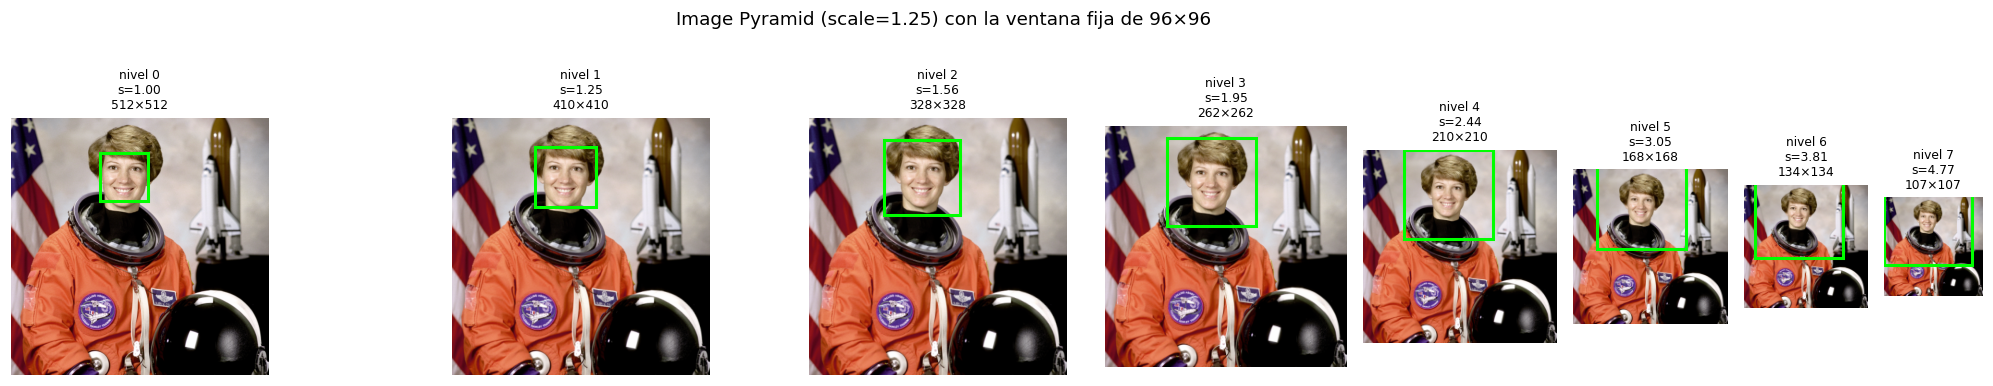

Ventanas por nivel (step=16): [729, 400, 225, 121, 64, 25, 9, 1] · total: 1574


In [4]:
img_demo = data.astronaut()
niveles = list(image_pyramid(img_demo, 1.25, WINDOW))
fig, axs = plt.subplots(1, len(niveles), figsize=(2.4 * len(niveles), 3.4),
                        gridspec_kw={"width_ratios": [im.shape[1] for _, _, im in niveles]})
cx, cy = 225, 118   # centro aproximado del rostro en la imagen original
for ax, (l, s, im) in zip(axs, niveles):
    ax.imshow(im)
    ax.add_patch(plt.Rectangle((cx / s - 48, cy / s - 48), 96, 96, fill=False, ec="lime", lw=2))
    ax.set_title(f"nivel {l}\ns={s:.2f}\n{im.shape[1]}×{im.shape[0]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Image Pyramid (scale=1.25) con la ventana fija de 96×96", y=1.02)
plt.tight_layout(); plt.savefig("piramide_imagenes.png", bbox_inches="tight"); plt.show()

# Conteo de ventanas por nivel
n_ventanas = [sum(1 for _ in sliding_window(im, 16, WINDOW)) for _, _, im in niveles]
print("Ventanas por nivel (step=16):", n_ventanas, "· total:", sum(n_ventanas))

## 4 · Dataset de evaluación (3 casos)
| Caso | Descripción | Qué valida |
|---|---|---|
| 1 | `data.astronaut()` (512×512): rostro mediano sobre fondo estructurado | Ubicación + escala ≈ ventana |
| 2 | Retrato con rostro dominante (~200×260 px) | Niveles superiores de la pirámide (Desafío 2a) |
| 3 | `data.coffee()`: sin personas | Especificidad: **0 detecciones** |

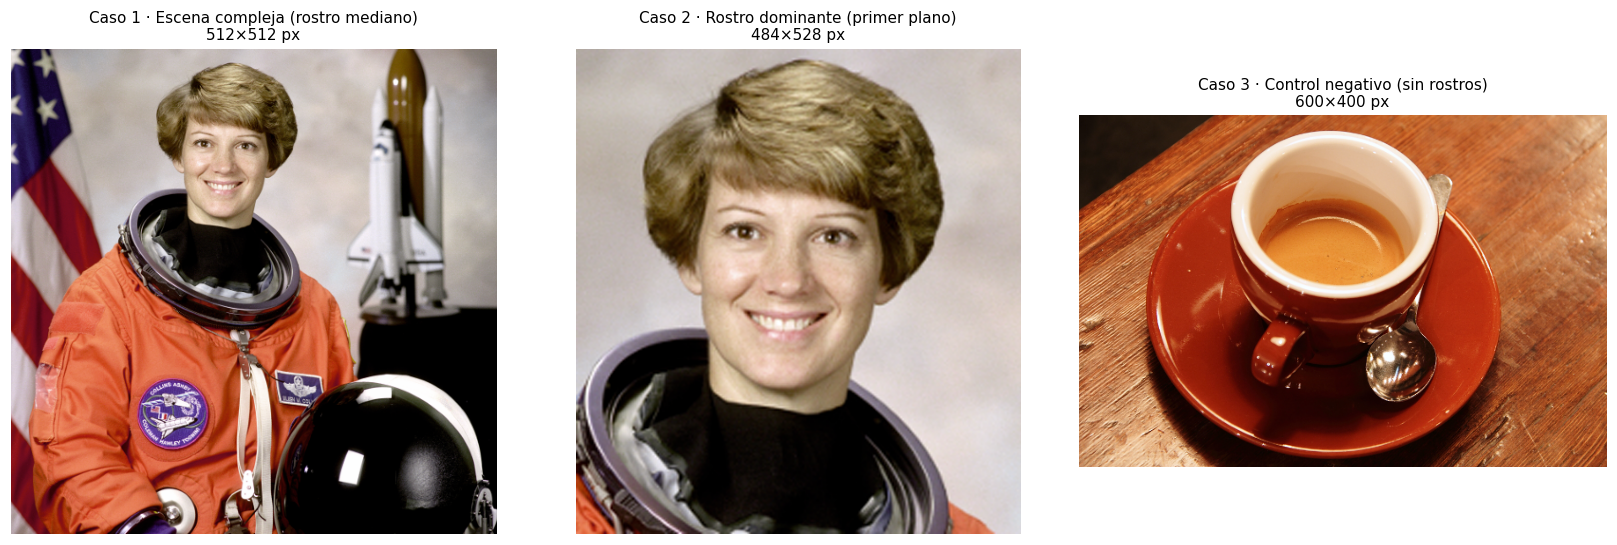

In [5]:
def preparar_casos():
    astro = data.astronaut()                                   # Caso 1
    recorte = astro[10:250, 120:340]                           # cabeza y hombros
    retrato = cv2.resize(recorte, None, fx=2.2, fy=2.2, interpolation=cv2.INTER_CUBIC)  # Caso 2
    cafe = data.coffee()                                       # Caso 3
    return {
        1: ("Caso 1 · Escena compleja (rostro mediano)", astro),
        2: ("Caso 2 · Rostro dominante (primer plano)", retrato),
        3: ("Caso 3 · Control negativo (sin rostros)", cafe),
    }

casos = preparar_casos()
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, k in zip(axs, (1, 2, 3)):
    t, im = casos[k]
    ax.imshow(im); ax.set_title(f"{t}\n{im.shape[1]}×{im.shape[0]} px", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.savefig("dataset_evaluacion_deteccion.png", bbox_inches="tight"); plt.show()

## 5 · Benchmark paramétrico (Caso 1)
Tres configuraciones de escaneo sobre la imagen principal. Los parches de **todos los niveles** se acumulan en lotes de 32 y se procesan con un único `net.forward()` por lote.

In [6]:
CONFIGS = [("Paso Fino", 8, 1.15), ("Paso Estándar", 16, 1.25), ("Paso Rápido", 24, 1.40)]
img1_bgr = rgb2bgr(casos[1][1])

res_bench, filas = {}, []
for nombre, step, scale in CONFIGS:
    print(f"▶ {nombre} (step={step}, scale={scale}) ...", flush=True)
    r = detectar(img1_bgr, step, scale)
    res_bench[nombre] = r
    filas.append({
        "Configuración": nombre, "Step Size": step, "Scale Factor": scale,
        "Niveles de Pirámide": r["niveles"], "Total Ventanas Evaluadas": r["total_ventanas"],
        "Detecciones Brutas": r["detecciones_brutas"], "Detecciones Finales (NMS)": r["detecciones_finales"],
        "Tiempo Total (s)": round(r["tiempo_s"], 2),
        "Confianza máx.": round(float(r["scores"].max()), 4) if len(r["scores"]) else None,
    })
    print(f"   {r['total_ventanas']} ventanas · {r['detecciones_brutas']} brutas → {r['detecciones_finales']} finales · {r['tiempo_s']:.1f} s")

df = pd.DataFrame(filas)
df["Ventanas/s"] = (df["Total Ventanas Evaluadas"] / df["Tiempo Total (s)"]).round(1)
display(df)

▶ Paso Fino (step=8, scale=1.15) ...
   8676 ventanas · 78 brutas → 1 finales · 267.9 s
▶ Paso Estándar (step=16, scale=1.25) ...
   1574 ventanas · 15 brutas → 1 finales · 48.3 s
▶ Paso Rápido (step=24, scale=1.4) ...
   537 ventanas · 4 brutas → 1 finales · 16.6 s


,Configuración,Step Size,Scale Factor,Niveles de Pirámide,Total Ventanas Evaluadas,Detecciones Brutas,Detecciones Finales (NMS),Tiempo Total (s),Confianza máx.,Ventanas/s
0,Paso Fino,8,1.15,13,8676,78,1,267.88,1.0000,32.4
1,Paso Estándar,16,1.25,8,1574,15,1,48.30,1.0000,32.6
2,Paso Rápido,24,1.40,5,537,4,1,16.55,0.9993,32.4


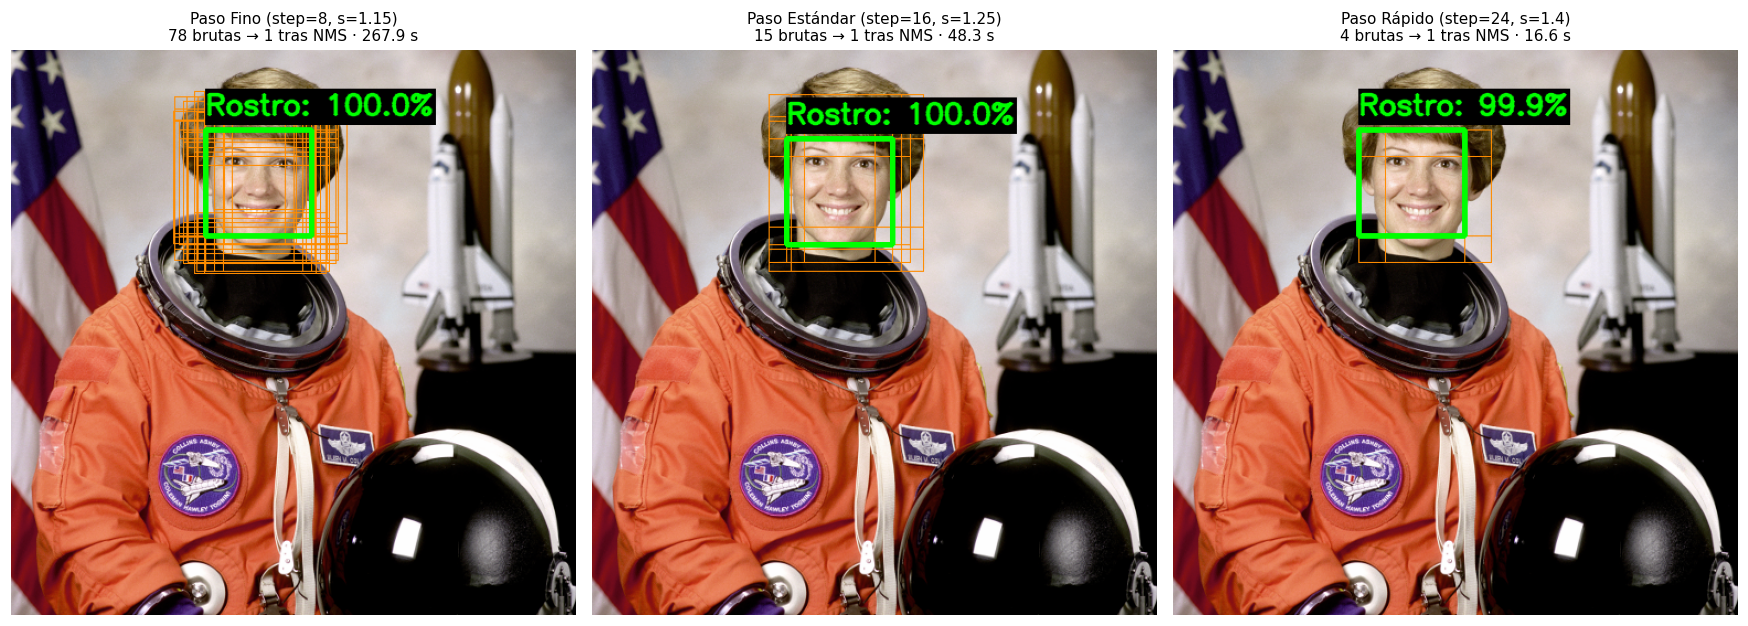

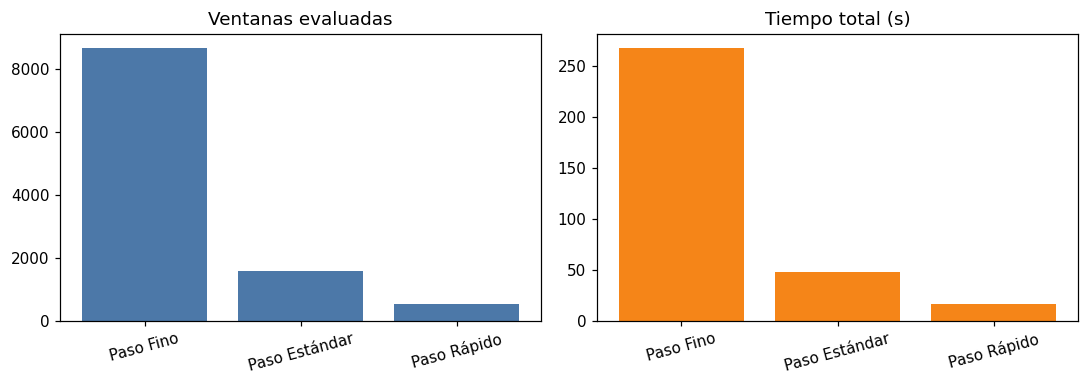

In [7]:
# --- Comparativa visual: detecciones brutas (naranja, 1 px) vs finales tras NMS (verde, 3 px)
fig, axs = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, (nombre, step, scale) in zip(axs, CONFIGS):
    r = res_bench[nombre]
    vis = img1_bgr.copy()
    for (x1, y1, x2, y2) in r["raw_boxes"]:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 140, 255), 1)
    vis = draw_detections(vis, r["boxes"], r["scores"])
    ax.imshow(bgr2rgb(vis)); ax.axis("off")
    ax.set_title(f"{nombre} (step={step}, s={scale})\n{r['detecciones_brutas']} brutas → {r['detecciones_finales']} tras NMS · {r['tiempo_s']:.1f} s", fontsize=10)
plt.tight_layout(); plt.savefig("comparativa_configuraciones.png", bbox_inches="tight"); plt.show()

# --- Costo vs configuración
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].bar(df["Configuración"], df["Total Ventanas Evaluadas"], color="#4c78a8"); axs[0].set_title("Ventanas evaluadas")
axs[1].bar(df["Configuración"], df["Tiempo Total (s)"], color="#f58518"); axs[1].set_title("Tiempo total (s)")
for a in axs: a.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig("benchmark_rendimiento.png", bbox_inches="tight"); plt.show()

## 6 · Galería de detección (configuración estándar: step=16, scale=1.25)
El Caso 1 reutiliza la ejecución *Paso Estándar* del benchmark; los casos 2 y 3 se evalúan con la misma configuración.

▶ Caso 2 ...
   1516 ventanas · 38 brutas → 1 finales · 46.7 s
▶ Caso 3 ...
   1397 ventanas · 0 brutas → 0 finales · 43.1 s


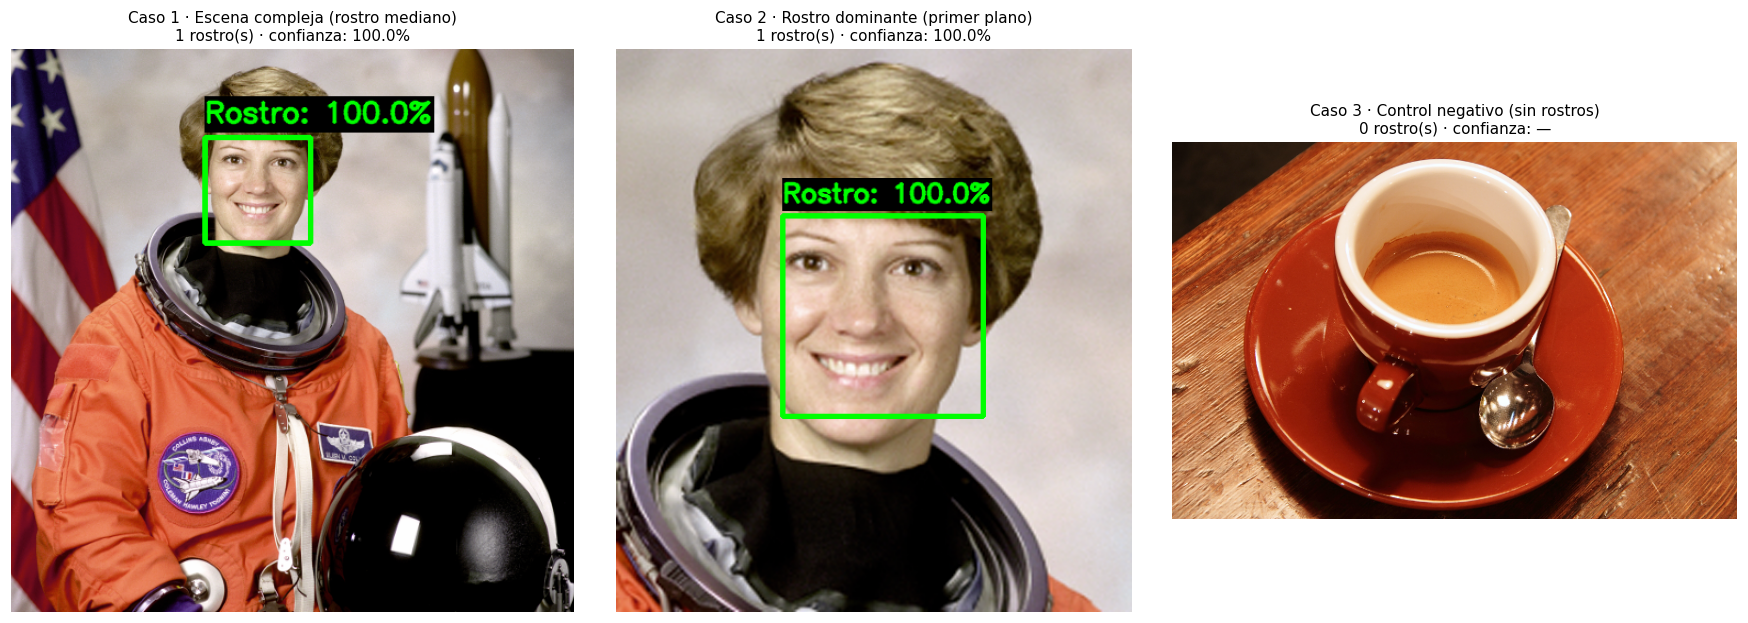

Caso 2: la caja final mide ≈188×188 px en la imagen original → factor ≈ 1.96 ≈ scale^3.0: detectada en un nivel superior de la pirámide.


In [8]:
res_casos = {1: res_bench["Paso Estándar"]}
for k in (2, 3):
    print(f"▶ Caso {k} ...", flush=True)
    res_casos[k] = detectar(rgb2bgr(casos[k][1]), 16, 1.25)
    r = res_casos[k]
    print(f"   {r['total_ventanas']} ventanas · {r['detecciones_brutas']} brutas → {r['detecciones_finales']} finales · {r['tiempo_s']:.1f} s")

fig, axs = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, k in zip(axs, (1, 2, 3)):
    t, im = casos[k]; r = res_casos[k]
    ax.imshow(bgr2rgb(draw_detections(rgb2bgr(im), r["boxes"], r["scores"])))
    conf = ", ".join(f"{s*100:.1f}%" for s in r["scores"]) or "—"
    ax.set_title(f"{t}\n{r['detecciones_finales']} rostro(s) · confianza: {conf}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.savefig("galeria_deteccion_rostros.png", bbox_inches="tight"); plt.show()

# Nivel de pirámide donde se ubicó la mejor ventana del Caso 2 (escala de la caja)
r2 = res_casos[2]
if len(r2["boxes"]):
    b = r2["boxes"][0]; lado = b[2] - b[0]
    print(f"Caso 2: la caja final mide ≈{lado}×{b[3]-b[1]} px en la imagen original → factor ≈ {lado/96:.2f} "
          f"≈ scale^{np.log(lado/96)/np.log(1.25):.1f}: detectada en un nivel superior de la pirámide.")

## 7 · Ablación 2×2 en el Caso 3 (control negativo)
Se prueban las combinaciones de **margen de contexto** (0 / 0.5) y **filtro de alineación** (apagado `min_cover=0` / 0.60). Cualquier detección es un falso positivo. Es solo una imagen: indica el efecto de cada mecanismo, no su importancia general.

▶ contexto=0.0 · alineación mínima=0.0 ...
▶ contexto=0.0 · alineación mínima=0.6 ...
▶ contexto=0.5 · alineación mínima=0.0 ...
▶ contexto=0.5 · alineación mínima=0.6 ...


,Contexto (× lado),Alineación mín.,Ventanas aceptadas,Detecciones finales,Confianza máx. FP,Tiempo (s)
0,0.0,0.0,3,1,0.924,43.2
1,0.0,0.6,0,0,0.000,43.4
2,0.5,0.0,0,0,0.000,44.0
3,0.5,0.6,0,0,0.000,37.7


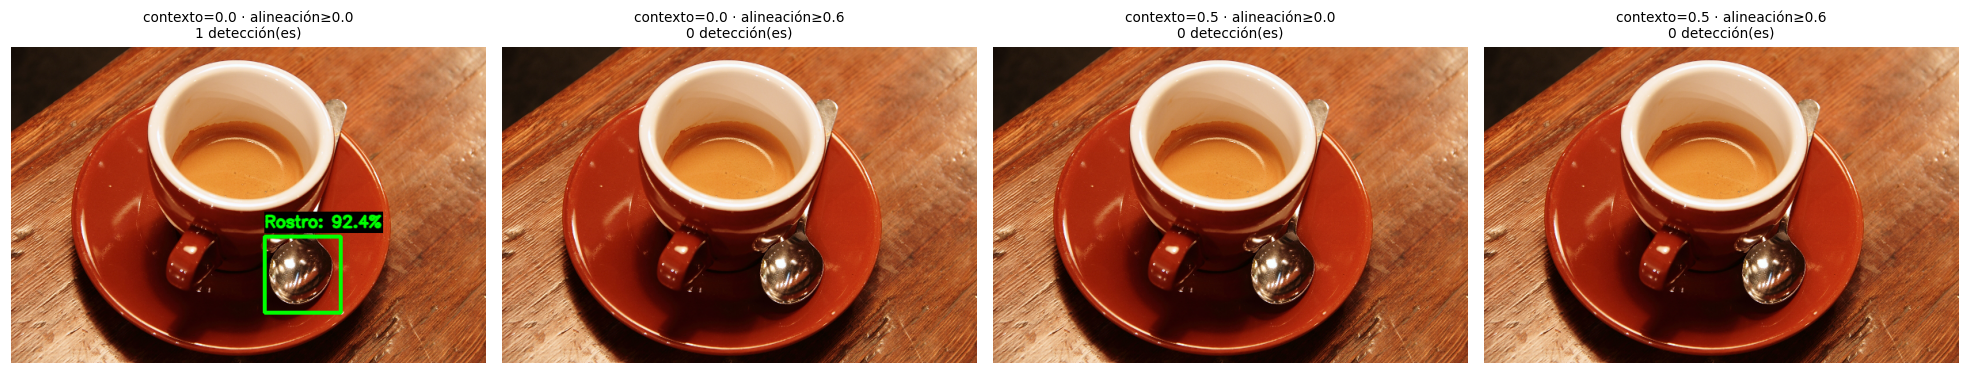

In [9]:
cafe_bgr = rgb2bgr(casos[3][1])
filas_abl, res_abl = [], {}
for ctx in (0.0, CONTEXT):
    for mc in (0.0, MIN_COVER):
        print(f"▶ contexto={ctx} · alineación mínima={mc} ...", flush=True)
        r = detectar(cafe_bgr, 16, 1.25, context=ctx, min_cover=mc)
        res_abl[(ctx, mc)] = r
        filas_abl.append({"Contexto (× lado)": ctx, "Alineación mín.": mc,
                          "Ventanas aceptadas": r["detecciones_brutas"],
                          "Detecciones finales": r["detecciones_finales"],
                          "Confianza máx. FP": round(float(r["scores"].max()), 3) if len(r["scores"]) else 0.0,
                          "Tiempo (s)": round(r["tiempo_s"], 1)})
df_abl = pd.DataFrame(filas_abl); display(df_abl)

fig, axs = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, ((ctx, mc), r) in zip(axs, res_abl.items()):
    ax.imshow(bgr2rgb(draw_detections(cafe_bgr, r["boxes"], r["scores"]))); ax.axis("off")
    ax.set_title(f"contexto={ctx} · alineación≥{mc}\n{r['detecciones_finales']} detección(es)", fontsize=9)
plt.tight_layout(); plt.savefig("ablacion_contexto.png", bbox_inches="tight"); plt.show()

## 8 · Análisis y conclusiones

**Costo computacional (ejecución de referencia en Kaggle).** El número de ventanas crece ≈ con 1/step² y con el número de niveles: Paso Fino evaluó 8 676 ventanas (13 niveles), Estándar 1 574 (8) y Rápido 537 (5). El rendimiento fue casi constante (~34 ventanas/s), así que **el tiempo es proporcional a las ventanas** (≈258 s, 46 s y 16 s): el paso fino cuesta ≈16× el rápido.

**Calidad en el Caso 1.** Las tres configuraciones terminan con **un único recuadro** sobre el rostro (confianza 1.000, 1.000 y 0.999). El paso fino produce muchas más ventanas aceptadas (78 vs 15 vs 4 brutas) que el NMS colapsa, pero **no mejora el resultado final**: la confianza ya satura y el recuadro es equivalente. *Conclusión práctica:* paso 16 con escala 1.25 (o incluso 24 con 1.40) ofrece el mejor compromiso costo/precisión en esta imagen. Con umbral 0.80 el paso fino llegó a aceptar una ventana sobre el transbordador del fondo (82.7 %), lo que ilustra por qué importa el umbral: más ventanas evaluadas implican más oportunidades de falsos positivos.

**Desafío 2a (rostro dominante).** En el Caso 2 el rostro mide ~200×260 px; la caja principal mide ≈188 px en la imagen original (≈ 96·1.25³), o sea, se detectó en el nivel 3 de la pirámide. La pirámide es lo que permite "encajar" un objeto grande en una ventana de tamaño fijo.

**Desafío 2b (ventana grande para el objeto).** Un rostro menor que la ventana (< ~96 px) no se detectaría con esta pirámide, que solo reduce la imagen; haría falta ampliar la imagen base (niveles con escala < 1) o usar una ventana menor.

**Falsos positivos y NMS.** Se necesitaron varios mecanismos: (i) filtro de alineación caja-ventana, (ii) prioridad confianza × alineación y (iii) supresión por contención. Sin el filtro de alineación, una primera versión devolvía 3 recuadros (Caso 1) y 10 (Caso 2) sobre un mismo rostro. En el Caso 2 el NMS clásico (IoU > 0.3) dejaba además un recuadro parcial sobre el mentón y el cuello (~90 % de confianza) porque el IoU con la caja principal era solo ≈0.2; la regla de contención lo elimina. La ablación 2×2 (sección 7) muestra que, en la imagen del café, el margen de contexto y el filtro de alineación eliminan **por separado** el falso positivo de la cuchara (0.924 tras NMS; hasta 0.978 en ventanas individuales); no se probó cuál pesa más en general.

**Limitaciones.** (1) El recuadro es la ventana cuadrada, no la caja ajustada del rostro (en el Caso 2 recorta parte de la frente). (2) Con entrada fija de 300×300, escanear con el SSD es lento; aplicado a la imagen completa el SSD tarda milisegundos y es la forma eficiente en producción, mientras que la ventana deslizante es el ejercicio didáctico. (3) Los umbrales (0.90, alineación 0.60, contención 0.40) se ajustaron mirando estas 3 imágenes; no hay conjunto de validación ni métricas de precisión/recall. (4) Rostros ocluidos, de perfil o < ~48 px pueden fallar.

## 9 · Exportación automática de entregables

In [10]:
def _lista(a): return np.asarray(a).tolist()

def resumen(r):
    return {"niveles": r["niveles"], "total_ventanas": r["total_ventanas"],
            "ventanas_por_nivel": r["ventanas_por_nivel"],
            "detecciones_brutas": r["detecciones_brutas"], "detecciones_finales": r["detecciones_finales"],
            "tiempo_s": round(r["tiempo_s"], 3),
            "cajas_finales_xyxy": _lista(r["boxes"]), "confianzas_finales": [round(float(s), 5) for s in r["scores"]]}

resultados = {
    "practica": "Práctica 6 · Detección de rostros (ventana deslizante + pirámide de imágenes)",
    "entorno": {"opencv": cv2.__version__, "numpy": np.__version__, "pandas": pd.__version__},
    "modelo": {"arquitectura": "ResNet-10 SSD (Caffe)", "prototxt": p6.PROTO_NAME, "pesos": p6.MODEL_NAME,
               "entrada_red": list(p6.NET_INPUT)},
    "parametros_globales": {"window_size": list(WINDOW), "conf_threshold": CONF_THR, "nms_overlap": NMS_THR,
                            "batch_size": BATCH, "min_alineacion": MIN_COVER, "context_margin": CONTEXT,
                            "contain_thresh": CONTAIN},
    "benchmark_caso1": [
        {**{k: (v if not isinstance(v, (np.integer, np.floating)) else v.item()) for k, v in fila.items()},
         "ventanas_por_nivel": res_bench[fila["Configuración"]]["ventanas_por_nivel"]}
        for fila in df.to_dict("records")
    ],
    "casos_configuracion_estandar": {casos[k][0]: {**resumen(res_casos[k]), "imagen_px": list(casos[k][1].shape[1::-1])}
                                      for k in (1, 2, 3)},
    "ablacion_caso3": df_abl.to_dict("records"),
}
ruta_json = os.path.join(OUT_DIR, "resultados_practica6.json")
with open(ruta_json, "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print("✔ JSON guardado:", ruta_json)

# Prueba del script por consola (Caso 2, configuración rápida)
cv2.imwrite("caso2_retrato.png", rgb2bgr(casos[2][1]))
p = subprocess.run([sys.executable, "practica_6_deteccion_rostros.py", "caso2_retrato.png",
                    "--step", "24", "--scale", "1.4", "--salida", "prueba_cli.png"],
                   capture_output=True, text=True)
print("\n$ python practica_6_deteccion_rostros.py caso2_retrato.png --step 24 --scale 1.4\n" + p.stdout + p.stderr[-300:])

print("\nArchivos exportados en", OUT_DIR)
for f in ["practica_6_deteccion_rostros.py", "resultados_practica6.json", "dataset_evaluacion_deteccion.png",
          "galeria_deteccion_rostros.png", "comparativa_configuraciones.png", "benchmark_rendimiento.png",
          "piramide_imagenes.png", "ablacion_contexto.png"]:
    ruta = os.path.join(OUT_DIR, f)
    print(("  ✔ " if os.path.exists(ruta) else "  ✘ ") + f, f"({os.path.getsize(ruta)/1024:.0f} KB)" if os.path.exists(ruta) else "")

✔ JSON guardado: /kaggle/working/resultados_practica6.json

$ python practica_6_deteccion_rostros.py caso2_retrato.png --step 24 --scale 1.4
Niveles: 5 | Ventanas: 535 | Brutas: 14 | Finales: 1 | Tiempo: 16.9 s
  Rostro 100.0%  caja=[141, 141, 329, 329]
Resultado guardado en prueba_cli.png


Archivos exportados en /kaggle/working
  ✔ practica_6_deteccion_rostros.py (16 KB)
  ✔ resultados_practica6.json (4 KB)
  ✔ dataset_evaluacion_deteccion.png (1117 KB)
  ✔ galeria_deteccion_rostros.png (1350 KB)
  ✔ comparativa_configuraciones.png (622 KB)
  ✔ benchmark_rendimiento.png (27 KB)
  ✔ piramide_imagenes.png (653 KB)
  ✔ ablacion_contexto.png (334 KB)
